# Modelo de abandono de clientes de un e-commerce

Preparación de datos y creación del modelo ganador.


El objetivo es la variable Churned: 1 si el cliente abandonó la plataforma y 0 si se quedó.

# Parte 1. Librerías

In [ ]:
# librerias para manejar datos y graficar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# librerias de scikit-learn para dividir, escalar, modelar y evaluar
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report, confusion_matrix)
from sklearn.inspection import permutation_importance

pd.set_option('display.max_columns', None)
SEMILLA = 42      # misma semilla para que todo se pueda repetir

# Parte 2. Cargar el dataset crudo

Se usa el archivo original ecommerce_customer_churn_dataset-1.csv tal como viene, con 50,000 clientes y 25 columnas.


In [ ]:
datos = pd.read_csv('ecommerce_customer_churn_dataset-1.csv')
print(datos.shape)
datos.head()

(50000, 25)


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14,27.4,6.0,50.6,3.0,9.0,94.72,34.0,46.40,2.0,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15,42.7,10.3,37.7,1.0,19.5,82.45,71.0,57.96,9.2,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10,24.8,1.6,70.9,1.0,9.1,165.52,11.0,12.24,11.5,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10,38.4,14.8,41.7,9.0,15.0,147.33,47.0,44.10,5.4,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29,51.4,NaN,19.1,9.0,32.5,141.30,73.0,25.20,5.5,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


# Parte 3. Exploración de los datos

In [ ]:
# tamaño, distribucion de la clase y tipos de variable
print('Filas y columnas:', datos.shape)
print()
print(datos.groupby('Churned').size())

#Calculamos la tasa de churn
print(f"Tasa de churn: {datos['Churned'].mean():.1%}")

#Siendo 1%, el formato de porcentaje con un decimal.

OBJ = "Churned"
CAT = ["Gender", "Country", "City", "Signup_Quarter"]

NUM = datos.select_dtypes(include="number").columns.tolist()
NUM.remove(OBJ)

#Aquí num hace una lista de los valores que son numéricos para entrenar el modelo y quitamos la variable objetivo.

print()
print("Numéricas:", len(NUM), "| Categóricas:", CAT)

Filas y columnas: (50000, 25)

Churned
0    35550
1    14450
dtype: int64
Tasa de churn: 28.9%

Numéricas: 20 | Categóricas: ['Gender', 'Country', 'City', 'Signup_Quarter']


El 28.9% de los clientes abandonó.
Las clases no están balanceadas, así que además del accuracy hay que ver el recall de la clase 1, es decir, cuántos de los que se van detecta el modelo.

In [ ]:
# estadisticas basicas: en min y max se asoman los errores
datos[NUM].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,47505.0,37.80,11.83,5.00,29.00,38.00,46.00,200.00
Membership_Years,50000.0,2.98,2.06,0.10,1.40,2.50,4.00,10.00
Login_Frequency,50000.0,11.62,7.81,0.00,6.00,11.00,17.00,46.00
Session_Duration_Avg,46601.0,27.66,10.87,1.00,19.70,26.80,34.70,75.60
Pages_Per_Session,47000.0,8.74,3.78,1.00,6.00,8.40,11.20,24.10
Cart_Abandonment_Rate,50000.0,57.08,16.28,0.00,46.40,58.10,68.70,143.74
Wishlist_Items,46000.0,4.30,3.19,0.00,2.00,4.00,6.00,28.00
Total_Purchases,50000.0,13.11,7.02,-13.00,8.00,12.00,17.00,128.70
Average_Order_Value,50000.0,123.12,175.57,26.38,87.05,112.97,144.44,9666.38
Days_Since_Last_Purchase,47000.0,29.79,29.70,0.00,9.00,21.00,41.00,287.00


Cosas que no tienen sentido:

1. Age tiene un mínimo de 5 y un máximo de 200 años.
2. Total_Purchases tiene negativos, y un conteo de compras no puede ser negativo.
3. Average_Order_Value tiene una mediana cercana a 113, pero el máximo pasa de 9,000.
4. Cart_Abandonment_Rate y Discount_Usage_Rate pasan de 100%.
5. Returns_Rate tiene una mediana de 5%, pero llega casi a 100%.

In [ ]:
# faltantes por columna
faltantes = pd.DataFrame({'faltantes': datos.isnull().sum(),
                          'porcentaje': (datos.isnull().mean() * 100).round(2)})
faltantes[faltantes['faltantes'] > 0].sort_values('porcentaje', ascending=False)

,faltantes,porcentaje
Social_Media_Engagement_Score,6000,12.00
Credit_Balance,5500,11.00
Mobile_App_Usage,5000,10.00
Returns_Rate,4491,8.98
Wishlist_Items,4000,8.00
Discount_Usage_Rate,3500,7.00
Product_Reviews_Written,3500,7.00
Session_Duration_Avg,3399,6.80
Pages_Per_Session,3000,6.00
Days_Since_Last_Purchase,3000,6.00


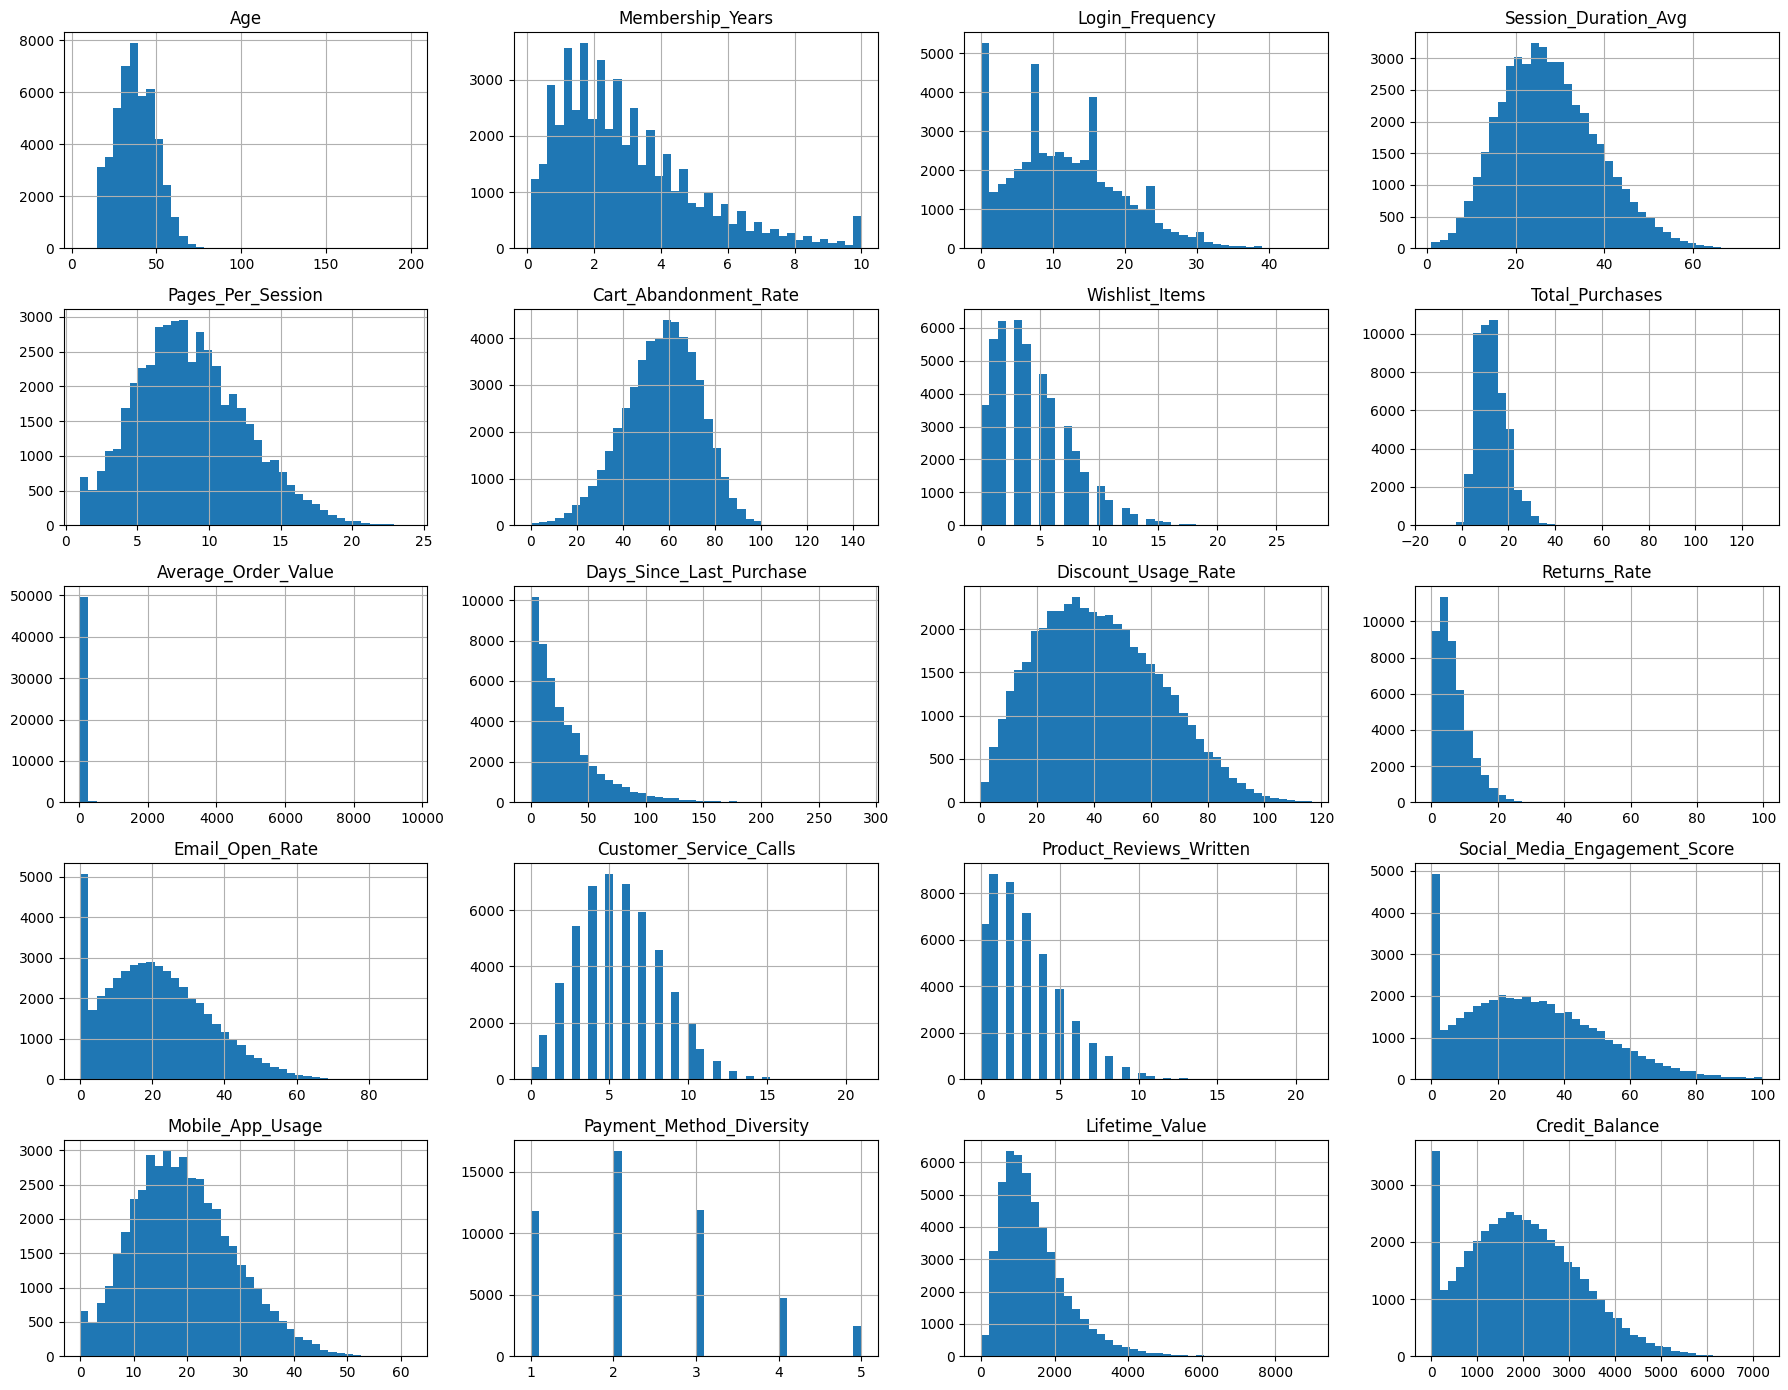

In [ ]:
# histogramas de las variables numericas
datos[NUM].hist(figsize=(18, 14), bins=40)
plt.tight_layout()
plt.show()

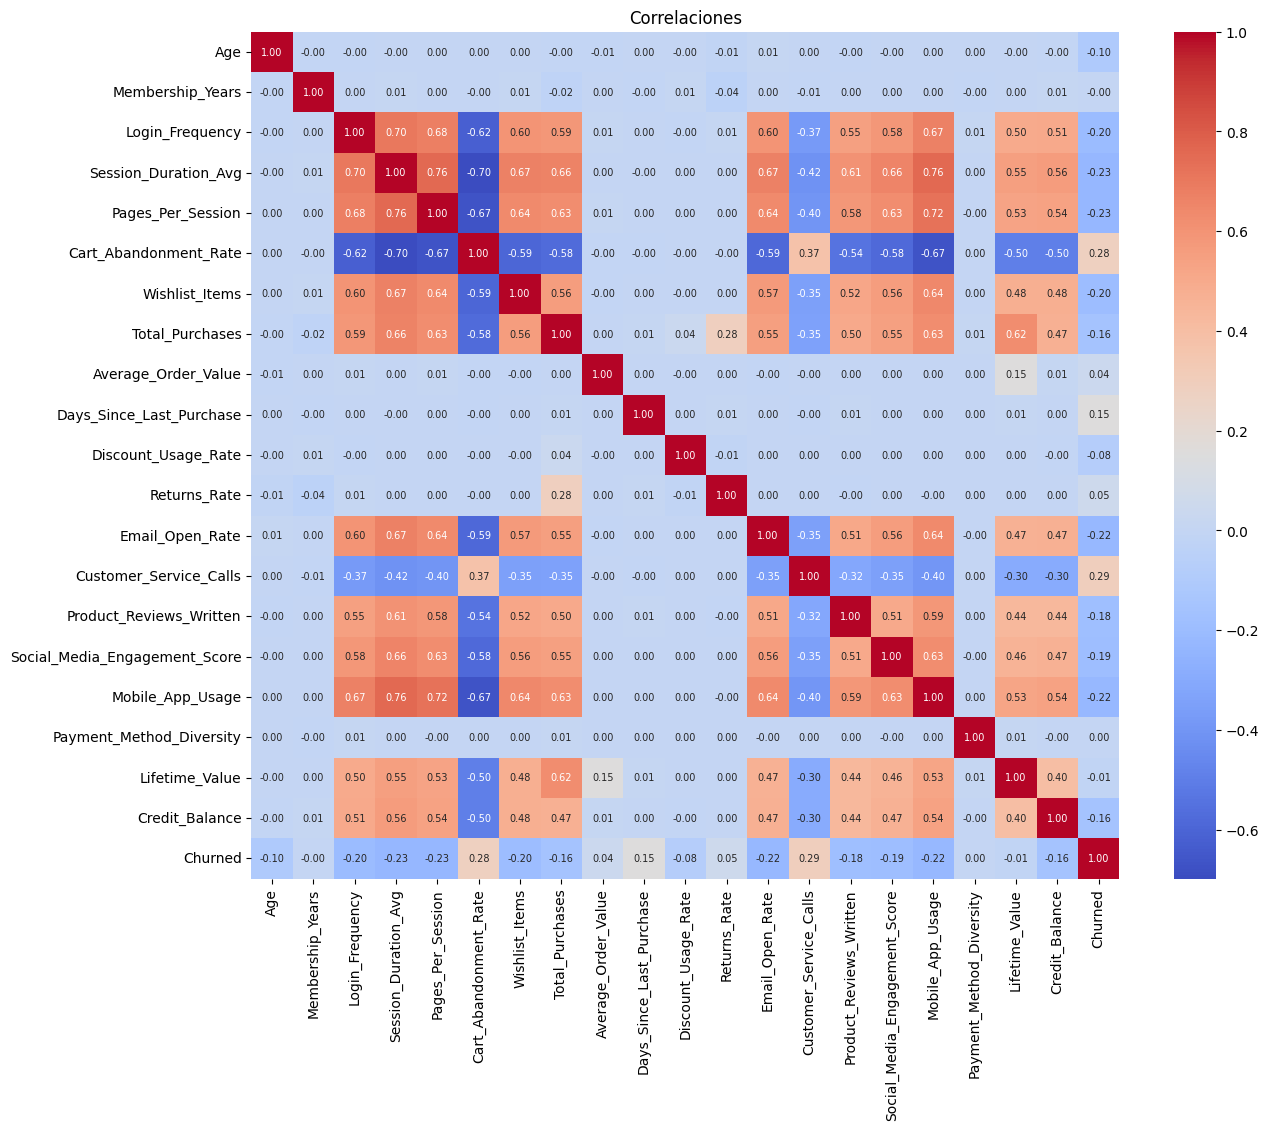

In [ ]:
# mapa de calor de correlaciones
corr = datos[NUM + [OBJ]].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Correlaciones')
plt.show()

Varias variables están muy sesgadas a la derecha (compras, ticket promedio, valor de vida, días desde la última compra). P

Por eso más adelante se transforman con logaritmo. Lifetime_Value se relaciona fuerte con Total_Purchases y Average_Order_Value, porque el valor de vida es más o menos compras por ticket promedio.

Esa relación es la que se usa para encontrar errores escondidos.

## Valores con decimales raros
Total_Purchases cuenta compras, así que debería ser un número entero. Se revisa si hay valores con decimales.

In [ ]:
# un conteo de compras deberia ser entero
tp = datos['Total_Purchases']
raros = tp[tp.notna() & (tp % 1 != 0)]
print('Valores con decimales:', len(raros))
print('Ejemplos:', raros.head(8).tolist())

# ¿son multiplos de 1.3?
print(f"Múltiplos exactos de 1.3: {((raros / 1.3).round(6) % 1 == 0).mean():.0%}")

Valores con decimales: 11241
Ejemplos: [19.5, 9.1, 32.5, 14.3, 6.5, 22.1, 15.6, 19.5]
Múltiplos exactos de 1.3: 100%


Hay 11,241 compras con decimales y todas son múltiplos exactos de 1.3. Por ejemplo, 19.5 es 15 × 1.3. Parece que a esos valores alguien los multiplicó por un factor. Para ver si pasa lo mismo en otras columnas, se lee el archivo otra vez, ahora como texto. Así pandas no redondea y se puede contar cuántos decimales trae cada valor.

In [ ]:
datos_txt = pd.read_csv("ecommerce_customer_churn_dataset-1.csv", dtype=str)

filas = []

for c in NUM:
    dec = datos_txt[c].str.split(".").str[1].fillna("").str.len()
    normal = dec.mode()[0]
    raros = datos_txt.loc[dec > normal, c]

    filas.append([c, normal, len(raros), raros.iloc[0] if len(raros) > 0 else ""])

conteo = pd.DataFrame(filas, columns=["Variable", "Decimales normales", "Valores raros", "Ejemplo"])

conteo[conteo["Valores raros"] > 0]

,Variable,Decimales normales,Valores raros,Ejemplo
1,Membership_Years,1,100,0.249093093
5,Cart_Abandonment_Rate,1,30,141.3905257
7,Total_Purchases,0,11241,19.5
8,Average_Order_Value,2,25,5279.800805
10,Discount_Usage_Rate,1,9277,57.96
11,Returns_Rate,1,100,81.51353276


Seis columnas tienen valores con más decimales de lo normal:
- Total_Purchases: 11,241 valores con decimales, múltiplos de 1.3.
- Discount_Usage_Rate: 9,277 valores con 2 decimales cuando lo normal es 1.
- Returns_Rate y Membership_Years: 100 valores cada una, con 8 o 9 decimales, en las mismas filas.
- Cart_Abandonment_Rate: 30 valores, y algunos pasan de 100%.
- Average_Order_Value: 25 valores, que además son mucho más grandes que el resto.

# Parte 4. División 80/20 antes de limpiar

Primero se separa el test y después se limpia. Si se limpiara todo junto, las medianas y los umbrales usarían información del test y el modelo se vería mejor de lo que es (fuga de información o data leakage). Es la regla que pidió el profesor.

Se usa una división estratificada para que train y test tengan la misma proporción de churn.

In [ ]:
# Separar datos en entrenamiento y prueba
train_crudo, test_crudo = train_test_split(
    datos, test_size=0.2, stratify=datos[OBJ], random_state=SEMILLA
)
# Separar también los datos en texto usando los mismos índices
train_txt = datos_txt.loc[train_crudo.index]
test_txt = datos_txt.loc[test_crudo.index]

print("Train:", train_crudo.shape, f"churn {train_crudo[OBJ].mean():.1%}")
print("Test:", test_crudo.shape, f"churn {test_crudo[OBJ].mean():.1%}")

# Crear copias para trabajar sin modificar los datos originales
train = train_crudo.copy()
test = test_crudo.copy()

# Lista para registrar los cambios realizados
bitacora = []

# Registrar los cambios
def anotar(variable, regla, filas_train, filas_test):
    bitacora.append({
        "variable": variable,
        "regla": regla,
        "filas train": int(filas_train),
        "filas test": int(filas_test)
    })

    print(f"{variable}: {regla} -> train {int(filas_train)}, test {int(filas_test)}")

Train: (40000, 25) churn 28.9%
Test: (10000, 25) churn 28.9%


# Parte 5. Limpieza variable por variable (solo train)

Cada regla se decide y se aplica solo en el train.

El test no se limpia ni se imputa: se queda como llegó, igual que llegarían los datos de clientes nuevos.

Los valores imposibles se vuelven faltantes y al final se imputan con la mediana del train.

Los valores que alguien multiplicó por un factor se regresan a su valor original dividiendo entre ese factor.

## 5.1 Age
Un cliente debe tener 18 años o más y nadie vive más de 100. Las edades de 5, 10, 150 y 200 son errores de captura.

No se usa clip, porque convertiría una edad de 200 en 80 e inventaría un cliente de 80 años.

In [ ]:
f_tr = (train['Age'] < 18) | (train['Age'] > 100)
print('Edades imposibles en train:', sorted(train.loc[f_tr, 'Age'].unique().tolist()))
train.loc[f_tr, 'Age'] = np.nan
anotar('Age', 'fuera de 18-100 -> faltante', f_tr.sum(), 0)

Edades imposibles en train: [5.0, 10.0, 150.0, 200.0]
Age: fuera de 18-100 -> faltante -> train 42, test 0


## 5.2 Average_Order_Value (marcar los inflados)

Average_Order_Value es el ticket promedio de cada cliente.

En la exploración vimos que la mediana es 113, pero el máximo pasa de 9,000. Se revisa paso a paso si esos valores tan altos son clientes reales o errores.

Paso 1. Ver cómo se reparten los valores con percentiles.

In [ ]:
# percentiles del ticket promedio en train
train['Average_Order_Value'].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(2)

,Average_Order_Value
count,40000.00
mean,123.40
std,180.34
min,26.38
50%,113.05
90%,178.93
99%,252.58
99.9%,336.60
max,9666.38


El 99.9% de los clientes tiene un ticket menor a 337, pero el máximo es 9,666. Hay unos pocos valores muy lejos del resto.

Paso 2. Ver los valores más altos, ordenados de mayor a menor.

In [ ]:
# los valores mas altos
train['Average_Order_Value'].sort_values(ascending=False).head(25).round(2).tolist()

[9666.38,
 9273.53,
 9229.2,
 9146.0,
 8757.53,
 8680.17,
 8507.21,
 8185.18,
 7921.15,
 7862.05,
 7672.79,
 7339.54,
 7227.08,
 7177.08,
 6590.32,
 6543.26,
 6454.33,
 6302.0,
 5502.31,
 5467.3,
 5279.8,
 5043.22,
 397.85,
 385.63,
 383.14]

Hay 22 valores entre 5,043 y 9,666, y después el siguiente baja de golpe a 397.85. No existe ningún cliente entre 398 y 5,043: son dos grupos separados. Cualquier corte en ese hueco los separa, así que se usa 1,000.

Paso 3. Marcar los valores arriba de 1,000.

In [ ]:
UMBRAL_AOV = 1000
aov_tr = train['Average_Order_Value'] > UMBRAL_AOV
print('Valores inflados en train:', aov_tr.sum())

Valores inflados en train: 22


Paso 4. Comprobar que son errores. El ticket promedio debería parecerse al valor de vida entre el número de compras (Lifetime_Value / Total_Purchases), porque el valor de vida es más o menos compras por ticket.

In [ ]:
# cuantas veces es el ticket comparado con valor de vida / compras
estimado = train['Lifetime_Value'] / train['Total_Purchases']
veces = train['Average_Order_Value'] / estimado

print('Valores normales: el ticket es', round(veces[~aov_tr].median(), 2), 'veces el estimado')
print('Valores inflados: el ticket es', round(veces[aov_tr].min(), 1), 'a', round(veces[aov_tr].max(), 1), 'veces el estimado')

Valores normales: el ticket es 1.07 veces el estimado
Valores inflados: el ticket es 37.7 a 132.9 veces el estimado


En los clientes normales el ticket es casi igual al estimado (1.07 veces). En los 22 marcados es entre 38 y 133 veces más grande. Por ejemplo, un cliente con valor de vida de 1,376 y 18 compras tendría un ticket cercano a 76, pero aparece con 9,273. Son errores de captura. Aquí solo se marcan; se corrigen en el paso 5.5, cuando Total_Purchases ya esté bien.

## 5.3 Total_Purchases (dividir entre 1.3)
Total_Purchases cuenta compras, así que debería ser un número entero.

Se revisa paso a paso de dónde salen los valores con decimales.

Paso 1. Ver qué valores con decimales aparecen.

In [ ]:
tp = train['Total_Purchases']
con_decimales = tp.notna() & (tp % 1 != 0)
print('Compras con decimales:', con_decimales.sum())

valores = np.sort(tp[con_decimales & (tp > 0)].unique())
print('Valores más chicos:', valores[:10])
print('Diferencia entre uno y el siguiente:', np.diff(valores[:10]).round(2))

Compras con decimales: 9019
Valores más chicos: [ 1.3  2.6  3.9  5.2  6.5  7.8  9.1 10.4 11.7 14.3]
Diferencia entre uno y el siguiente: [1.3 1.3 1.3 1.3 1.3 1.3 1.3 1.3 2.6]


Hay 9,019 compras con decimales y no son decimales al azar: los valores van de 1.3 en 1.3 (1.3, 2.6, 3.9, 5.2...). Son compras enteras multiplicadas por 1.3. Por ejemplo, 19.5 es 15 × 1.3.

Hay un detalle: de 11.7 salta a 14.3 y no aparece 13. Esto es porque 10 × 1.3 = 13, que es un entero, así que ese valor no trae decimales y se esconde entre las compras normales.

Paso 2. Confirmar el factor con otra columna. El valor de vida debería ser más o menos compras × ticket promedio, así que Lifetime_Value / (Total_Purchases × Average_Order_Value) debería dar cerca de 1. Si las compras están multiplicadas por 1.3, debería dar 1 / 1.3 = 0.77.

Compras enteras -> relación 0.99
Compras con decimales -> relación 0.769
1 / 1.3 = 0.769


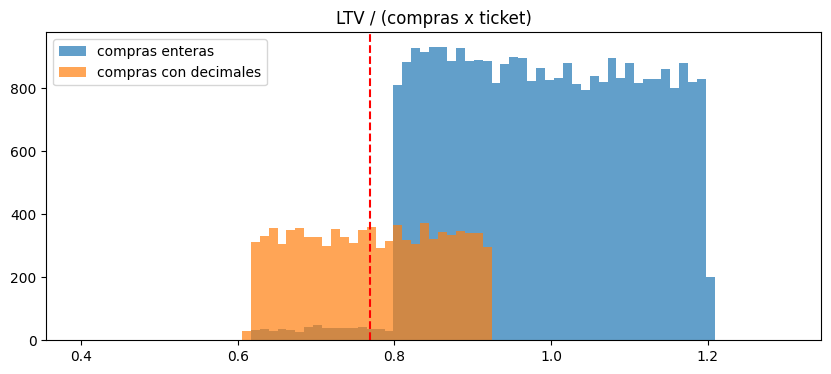

In [ ]:
def cociente(df):
    return df['Lifetime_Value'] / (df['Total_Purchases'] * df['Average_Order_Value'])

c0 = cociente(train)
ok = (train['Total_Purchases'] > 0) & ~aov_tr      # sin compras negativas ni tickets inflados

print('Compras enteras -> relación', round(c0[ok & ~con_decimales].median(), 3))
print('Compras con decimales -> relación', round(c0[ok & con_decimales].median(), 3))
print('1 / 1.3 =', round(1 / 1.3, 3))

plt.figure(figsize=(10, 4))
plt.hist(c0[ok & ~con_decimales], bins=np.linspace(0.4, 1.3, 80), alpha=0.7, label='compras enteras')
plt.hist(c0[ok & con_decimales], bins=np.linspace(0.4, 1.3, 80), alpha=0.7, label='compras con decimales')
plt.axvline(1 / 1.3, color='red', ls='--')
plt.title('LTV / (compras x ticket)')
plt.legend()
plt.show()

Con compras enteras la relación da 0.99, como se esperaba. Con compras con decimales da 0.769, exactamente 1 / 1.3. Dos columnas distintas confirman el mismo factor.

Paso 3. Buscar los casos escondidos. Si 10 compras × 1.3 = 13, también 20 × 1.3 = 26, 30 × 1.3 = 39, etc. Son enteros y múltiplos de 13. Se compara su relación con la del resto de compras enteras.

In [ ]:
enteras = ok & ~con_decimales
mult13 = enteras & (tp % 13 == 0)
otras = enteras & (tp % 13 != 0)

print('Múltiplos de 13:', mult13.sum(), '| con relación < 0.8:', (c0[mult13] < 0.8).sum())
print('Resto de compras enteras:', otras.sum(), '| con relación < 0.8:', (c0[otras] < 0.8).sum())

Múltiplos de 13: 2970 | con relación < 0.8: 595
Resto de compras enteras: 27965 | con relación < 0.8: 55


De los 2,970 clientes con compras múltiplos de 13, 595 (20%) tienen la relación por debajo de 0.8, igual que los multiplicados por 1.3. En el resto de compras enteras casi no pasa (55 casos, 0.2%). Esos 595 también se dividen entre 1.3. Los múltiplos de 13 con relación normal son compras reales y no se tocan.

Paso 4. Corregir: dividir entre 1.3 las compras con decimales y los casos escondidos.

In [ ]:
LIMITE_COCIENTE = 0.8

tp = train['Total_Purchases']
c = cociente(train)
a = tp % 1 != 0                                                                       # con decimales
b = (tp % 1 == 0) & (tp > 0) & (tp % 13 == 0) & (c < LIMITE_COCIENTE) & ~aov_tr      # escondidos
train.loc[a | b, 'Total_Purchases'] = (tp[a | b] / 1.3).round()

anotar('Total_Purchases', 'con decimales / 1.3', a.sum(), 0)
anotar('Total_Purchases', '13, 26, 39... con relación < 0.8 / 1.3', b.sum(), 0)

c1 = cociente(train)
print(f'Filas con relación < 0.8 -> antes {(c0[ok] < 0.8).mean():.1%} | después {(c1[ok] < 0.8).mean():.2%}')

Total_Purchases: con decimales / 1.3 -> train 9019, test 0
Total_Purchases: 13, 26, 39... con relación < 0.8 / 1.3 -> train 595, test 0
Filas con relación < 0.8 -> antes 15.1% | después 0.21%


## 5.4 Total_Purchases negativos

No se puede comprar un número negativo de veces. Esta revisión va después del paso anterior porque algunos negativos también estaban multiplicados por 1.3 (por ejemplo, −10.4 ya se convirtió en −8). Aunque se corrija el factor, siguen siendo negativos, así que no se puede saber el valor real y pasan a faltante.

In [ ]:
f_tr = train['Total_Purchases'] < 0
print('Compras negativas en train:', f_tr.sum())
print('Valores:', sorted(train.loc[f_tr, 'Total_Purchases'].unique().tolist()))

train.loc[f_tr, 'Total_Purchases'] = np.nan
anotar('Total_Purchases', 'negativo -> faltante', f_tr.sum(), 0)

Compras negativas en train: 32
Valores: [-13.0, -10.0, -9.0, -8.0, -7.0, -6.0, -5.0, -4.0, -3.0, -2.0, -1.0]
Total_Purchases: negativo -> faltante -> train 32, test 0


## 5.5 Average_Order_Value (recalcular los inflados)

Para los 22 valores marcados en la 5.2, el ticket promedio real se recalcula con datos del mismo cliente: Lifetime_Value / Total_Purchases. Va después de la 5.3 y la 5.4 porque necesita las compras ya corregidas.

importante: No usa información de otros clientes, así que no hay fuga.

In [ ]:
# ticket estimado con datos del mismo cliente
nuevo = (train['Lifetime_Value'] / train['Total_Purchases']).round(2)

antes = train.loc[aov_tr, 'Average_Order_Value'].copy()
train.loc[aov_tr, 'Average_Order_Value'] = nuevo[aov_tr]
anotar('Average_Order_Value', f'> {UMBRAL_AOV} -> LTV / compras', aov_tr.sum(), 0)

# comprobar que los valores nuevos caen en el rango normal
print('Valores corregidos: de', train.loc[aov_tr, 'Average_Order_Value'].min(), 'a', train.loc[aov_tr, 'Average_Order_Value'].max())
print('Resto de clientes: de', train.loc[~aov_tr, 'Average_Order_Value'].min(), 'a', train.loc[~aov_tr, 'Average_Order_Value'].max())
pd.DataFrame({'antes': antes.round(2), 'después': train.loc[aov_tr, 'Average_Order_Value']}).head()

Average_Order_Value: > 1000 -> LTV / compras -> train 22, test 0
Valores corregidos: de 48.58 a 210.0
Resto de clientes: de 26.38 a 397.85


,antes,después
38534,9273.53,76.45
16297,9146.00,147.59
41673,5043.22,84.86
16969,7339.54,90.41
15588,8507.21,210.00


Los 22 valores pasan de entre 5,043 y 9,666 a entre 48.58 y 210, dentro del rango del resto de los clientes (26 a 398). La corrección los regresa a valores normales.

## 5.6 Discount_Usage_Rate (dividir entre 1.2)

Discount_Usage_Rate es el porcentaje de compras con descuento. En la Parte 3 vimos que lo normal es que traiga 1 decimal, pero miles de valores traen 2.

Paso 1. Ver cuántos valores son raros: con 2 o más decimales, o mayores a 100%.

In [ ]:
datos_txt = pd.read_csv("ecommerce_customer_churn_dataset-1.csv", dtype=str)

# cuenta los digitos despues del punto: '81.51353276' -> 8 (se usa otra vez en la Parte 5)
def decimales(serie_txt):
    return serie_txt.str.split(".").str[1].fillna("").str.len()

filas = []

for c in NUM:
    dec = decimales(datos_txt[c])
    normal = dec.mode()[0]
    raros = datos_txt.loc[dec > normal, c]

    filas.append([c, normal, len(raros), raros.iloc[0] if len(raros) > 0 else ""])

conteo = pd.DataFrame(filas, columns=["Variable", "Decimales normales", "Valores raros", "Ejemplo"])

conteo[conteo["Valores raros"] > 0]

,Variable,Decimales normales,Valores raros,Ejemplo
1,Membership_Years,1,100,0.249093093
5,Cart_Abandonment_Rate,1,30,141.3905257
7,Total_Purchases,0,11241,19.5
8,Average_Order_Value,2,25,5279.800805
10,Discount_Usage_Rate,1,9277,57.96
11,Returns_Rate,1,100,81.51353276


Hay 7,478 valores con 2 decimales y 162 mayores a 100% (la mayoría son los mismos). Valores como 71.04 o 42.36 no aparecen en el resto de la columna.

Paso 2. Encontrar el factor. Si alguien multiplicó los valores, al dividirlos entre el factor correcto deberían regresar a 1 decimal exacto. Se prueban varios factores.

In [ ]:
desc = train['Discount_Usage_Rate']
dos_dec = desc.notna() & (decimales(train_txt['Discount_Usage_Rate']) >= 2)
mayor_100 = desc > 100

print('Con 2 o más decimales:', dos_dec.sum())
print('Mayores a 100%:', mayor_100.sum())
print('Ejemplos:', desc[dos_dec].head(6).tolist())

Con 2 o más decimales: 7478
Mayores a 100%: 162
Ejemplos: [71.04, 81.12, 42.36, 24.84, 13.08, 46.56]


Hay 7,478 valores con 2 decimales y 162 mayores a 100% (la mayoría son los mismos). Valores como 71.04 o 42.36 no aparecen en el resto de la columna.

Paso 2. Encontrar el factor. Si alguien multiplicó los valores, al dividirlos entre el factor correcto deberían regresar a 1 decimal exacto. Se prueban varios factores.

In [ ]:
raros = desc[dos_dec]
for factor in [1.1, 1.2, 1.25, 1.3, 1.5]:
    dividido = raros / factor * 10
    exactos = (dividido - dividido.round()).abs() < 0.000001
    print(f'Entre {factor}: {exactos.mean():.0%} regresan a 1 decimal')

Entre 1.1: 9% regresan a 1 decimal
Entre 1.2: 100% regresan a 1 decimal
Entre 1.25: 0% regresan a 1 decimal
Entre 1.3: 8% regresan a 1 decimal
Entre 1.5: 0% regresan a 1 decimal


Solo con 1.2 todos (100%) regresan a 1 decimal exacto. Con los demás factores casi ninguno. Además, la mediana de los valores raros es 46.1 y la de los sanos 38.8; al dividir los raros entre 1.2 su mediana queda en 38.4, igual que la de los sanos.

Paso 3. Corregir: dividir entre 1.2 los valores con 2 decimales y los mayores a 100%.

Discount_Usage_Rate: 2+ decimales o > 100 -> / 1.2 -> train 7513, test 0
Máximo antes 116.64 | después 99.60


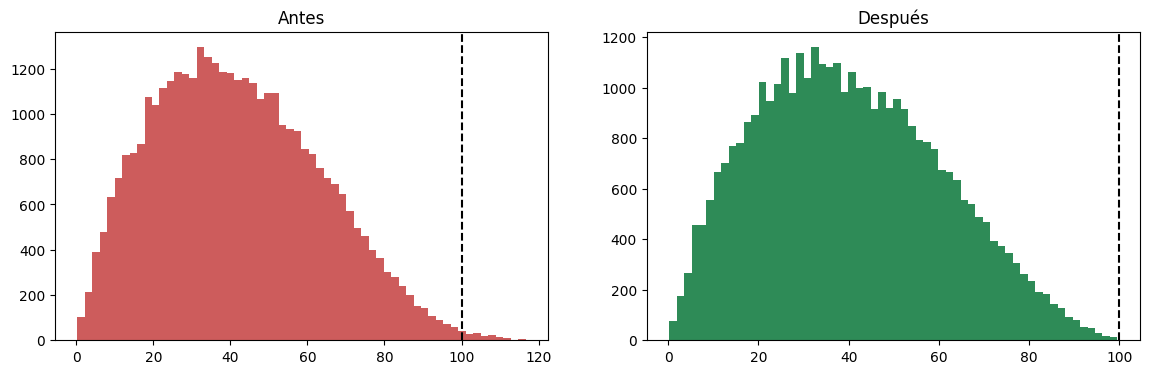

In [ ]:
d0 = desc.copy()
f_tr = dos_dec | mayor_100
train.loc[f_tr, 'Discount_Usage_Rate'] = (d0[f_tr] / 1.2).round(1)
anotar('Discount_Usage_Rate', '2+ decimales o > 100 -> / 1.2', f_tr.sum(), 0)
print(f"Máximo antes {d0.max():.2f} | después {train['Discount_Usage_Rate'].max():.2f}")

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].hist(d0.dropna(), bins=60, color='indianred'); axs[0].axvline(100, color='k', ls='--')
axs[0].set_title('Antes')
axs[1].hist(train['Discount_Usage_Rate'].dropna(), bins=60, color='seagreen'); axs[1].axvline(100, color='k', ls='--')
axs[1].set_title('Después')
plt.show()

Se corrigieron 7,513 valores y ninguno pasa ya de 100% (el máximo queda en 99.6). Limitación: si el valor original terminaba en .0 o .5, al multiplicarlo por 1.2 sigue teniendo 1 decimal y no se puede detectar, salvo que pase de 100%. Por eso se incluyen los mayores a 100%: 35 de ellos tienen 1 decimal y solo así se detectan.

## 5.7 Cart_Abandonment_Rate

Cart_Abandonment_Rate es el porcentaje de carritos que el cliente abandona, así que debe estar entre 0 y 100. Se revisa si hay valores fuera de ese rango.

In [ ]:
carrito = train['Cart_Abandonment_Rate']
mayor_100 = carrito > 100
muchos_dec = decimales(train_txt['Cart_Abandonment_Rate']) >= 3

print('Mayores a 100%:', mayor_100.sum())
print('Valores:', sorted(carrito[mayor_100].round(2).tolist()))
print('De ellos, con 3 o más decimales:', (mayor_100 & muchos_dec).sum())

Mayores a 100%: 22
Valores: [100.66, 101.2, 101.32, 102.13, 102.48, 103.47, 103.54, 103.91, 107.64, 109.13, 111.19, 116.71, 117.22, 118.46, 125.25, 125.4, 126.05, 126.22, 129.31, 134.96, 137.01, 143.74]
De ellos, con 3 o más decimales: 22


Hay 22 valores entre 100.66% y 143.74%, y los 22 traen muchos decimales cuando lo normal es 1. No siguen un factor como en Total_Purchases o Discount_Usage_Rate (no son múltiplos de un mismo número), así que no se pueden regresar a su valor real. Pasan a faltante y se imputan.

In [ ]:
train.loc[mayor_100, 'Cart_Abandonment_Rate'] = np.nan
anotar('Cart_Abandonment_Rate', '> 100 -> faltante', mayor_100.sum(), 0)

Cart_Abandonment_Rate: > 100 -> faltante -> train 22, test 0


## 5.8 Returns_Rate y Membership_Years
En la Parte 3 vimos que Returns_Rate y Membership_Years tienen algunos valores con muchos más decimales de lo normal. Se revisa paso a paso si son datos reales.

Paso 1. Contar los valores con 3 o más decimales en cada columna y ver si son las mismas filas.

In [ ]:
dev_raro = decimales(train_txt['Returns_Rate']) >= 3
ant_raro = decimales(train_txt['Membership_Years']) >= 3

print('Returns_Rate con 3+ decimales:', dev_raro.sum())
print('Membership_Years con 3+ decimales:', ant_raro.sum())
print('En la misma fila:', (dev_raro & ant_raro).sum())

Returns_Rate con 3+ decimales: 85
Membership_Years con 3+ decimales: 85
En la misma fila: 85


In [ ]:
f_tr = dev_raro & ant_raro

print(f"Returns_Rate en esas filas: {train.loc[f_tr, 'Returns_Rate'].min():.1f} a {train.loc[f_tr, 'Returns_Rate'].max():.1f}")
print(f"Returns_Rate en el resto: máximo {train.loc[~f_tr, 'Returns_Rate'].max():.1f}")
print(f"Membership_Years en esas filas: {train.loc[f_tr, 'Membership_Years'].min():.2f} a {train.loc[f_tr, 'Membership_Years'].max():.2f}")
print(f"Membership_Years en el resto: mediana {train.loc[~f_tr, 'Membership_Years'].median():.1f}")
train.loc[f_tr, ['Returns_Rate', 'Membership_Years']].head()

Returns_Rate en esas filas: 80.2 a 99.6
Returns_Rate en el resto: máximo 39.4
Membership_Years en esas filas: 0.11 a 0.49
Membership_Years en el resto: mediana 2.5


,Returns_Rate,Membership_Years
22783,99.220802,0.212937
27396,91.412821,0.267991
12350,80.757983,0.134141
35715,96.091291,0.176096
37706,96.882806,0.173565


En esas 85 filas Returns_Rate va de 80% a 99.6%, cuando ningún otro cliente pasa de 39.4%. Además, todos tendrían menos de medio año de antigüedad (0.11 a 0.49 años), cuando la mediana es 2.5. Clientes nuevos que devuelven casi todo lo que compran, con valores llenos de decimales: son datos inventados. No siguen un factor, así que no se puede saber el valor real. Las dos celdas pasan a faltante y se imputan.

In [ ]:
train.loc[f_tr, ['Returns_Rate', 'Membership_Years']] = np.nan
anotar('Returns_Rate y Membership_Years', '3+ decimales a la vez -> faltante', f_tr.sum(), 0)

Returns_Rate y Membership_Years: 3+ decimales a la vez -> faltante -> train 85, test 0


## 5.9 Variables que se revisaron y no se cambian
Las demás variables numéricas se revisan con los mismos criterios de los pasos anteriores: que estén en un rango posible, que no tengan decimales raros y que no tengan saltos grandes entre sus valores más altos, como el de Average_Order_Value (×12.7).

In [ ]:
SIN_CAMBIOS = ['Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Wishlist_Items',
               'Days_Since_Last_Purchase', 'Email_Open_Rate', 'Customer_Service_Calls',
               'Product_Reviews_Written', 'Social_Media_Engagement_Score', 'Mobile_App_Usage',
               'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance']

def salto_mayor(serie):
    # el salto mas grande entre los 50 valores mas altos (cuantas veces es uno del anterior)
    orden = np.sort(serie.dropna().values)[-51:]
    orden = orden[orden > 0]
    return round((orden[1:] / orden[:-1]).max(), 2)

pd.DataFrame({'mín': train[SIN_CAMBIOS].min(),
              'máx': train[SIN_CAMBIOS].max(),
              'faltantes': train[SIN_CAMBIOS].isnull().sum(),
              'salto mayor': [salto_mayor(train[c]) for c in SIN_CAMBIOS]})

,mín,máx,faltantes,salto mayor
Login_Frequency,0.0,44.00,0,1.03
Session_Duration_Avg,1.0,75.60,2689,1.05
Pages_Per_Session,1.0,23.90,2359,1.03
Wishlist_Items,0.0,28.00,3210,1.22
Days_Since_Last_Purchase,0.0,283.00,2412,1.07
Email_Open_Rate,0.0,91.70,2018,1.12
Customer_Service_Calls,0.0,21.00,140,1.11
Product_Reviews_Written,0.0,21.00,2772,1.31
Social_Media_Engagement_Score,0.0,100.00,4765,1.01
Mobile_App_Usage,0.0,61.90,4013,1.08


Ninguna tiene negativos ni porcentajes arriba de 100, y el salto más grande entre sus valores más altos es de 1.31 veces (Product_Reviews_Written), muy lejos del ×12.7 de Average_Order_Value. Los valores altos son continuos, así que son clientes reales extremos, no errores; el logaritmo reduce su peso. Estas variables solo tienen faltantes, que se imputan en la 5.10.

También se revisa si la antigüedad tiene sentido con la edad: un cliente no debería haberse registrado antes de los 13 años.

In [ ]:
edad_registro = train['Age'] - train['Membership_Years']
print('Clientes que se habrían registrado antes de los 13 años:', (edad_registro < 13).sum())

Clientes que se habrían registrado antes de los 13 años: 397


Hay 397 clientes así. No se sabe si está mal la edad o la antigüedad, y los dos valores por separado son posibles, así que no se tocan. Se menciona como limitación del dataset.

Por último, las variables categóricas: se revisa que no tengan errores de escritura y que train y test tengan las mismas categorías.

In [ ]:
for c in CAT:
    print(c, '| categorías:', train[c].nunique(), '| iguales en train y test:', set(train[c]) == set(test[c]))
    print('  ', sorted(train[c].unique())[:10])

Gender | categorías: 3 | iguales en train y test: True
   ['Female', 'Male', 'Other']
Country | categorías: 8 | iguales en train y test: True
   ['Australia', 'Canada', 'France', 'Germany', 'India', 'Japan', 'UK', 'USA']
City | categorías: 40 | iguales en train y test: True
   ['Adelaide', 'Bangalore', 'Berlin', 'Birmingham', 'Brisbane', 'Calgary', 'Chennai', 'Chicago', 'Cologne', 'Delhi']
Signup_Quarter | categorías: 4 | iguales en train y test: True
   ['Q1', 'Q2', 'Q3', 'Q4']


Las cuatro variables categóricas tienen categorías bien escritas y las mismas en train y test (3 géneros, 8 países, 40 ciudades y 4 trimestres).

Comprobación final: rangos de las variables corregidas, antes y después de la limpieza.

## 5.10 Imputación de faltantes (solo train)

No todos los faltantes significan lo mismo, así que antes de rellenarlos se revisa cada variable.

Paso 1. Cuántos faltantes tiene cada variable en el train. Incluye los originales y los que se crearon con las reglas de los pasos anteriores.

In [ ]:
falt = train[NUM].isnull().sum()
falt[falt > 0].sort_values(ascending=False)

,0
Social_Media_Engagement_Score,4765
Credit_Balance,4353
Mobile_App_Usage,4013
Returns_Rate,3695
Wishlist_Items,3210
Discount_Usage_Rate,2828
Product_Reviews_Written,2772
Session_Duration_Avg,2689
Days_Since_Last_Purchase,2412
Pages_Per_Session,2359


¿Un vacío significa 0? Varias variables ya tienen clientes con 0 registrado. Se compara el abandono de tres grupos: los que tienen 0, los que tienen el dato vacío y los que tienen un valor mayor a 0.

In [ ]:
con_ceros = ['Wishlist_Items', 'Product_Reviews_Written', 'Social_Media_Engagement_Score',
             'Credit_Balance', 'Mobile_App_Usage', 'Email_Open_Rate']

filas = []
for c in con_ceros:
    filas.append([c,
                  (train[c] == 0).sum(),
                  train.loc[train[c] == 0, OBJ].mean() * 100,
                  train.loc[train[c].isnull(), OBJ].mean() * 100,
                  train.loc[train[c] > 0, OBJ].mean() * 100])

pd.DataFrame(filas, columns=['Variable', 'Clientes con 0', 'Abandono con 0 (%)',
                             'Abandono sin dato (%)', 'Abandono > 0 (%)']).set_index('Variable').round(1)

,Clientes con 0,Abandono con 0 (%),Abandono sin dato (%),Abandono > 0 (%)
Variable,,,,
Wishlist_Items,2949,60.3,28.7,26.2
Product_Reviews_Written,5357,50.5,30.3,25.1
Social_Media_Engagement_Score,3129,51.0,29.9,26.6
Credit_Balance,2197,47.7,29.5,27.6
Mobile_App_Usage,287,70.4,28.8,28.6
Email_Open_Rate,3023,59.4,40.7,25.6


Un vacío no significa 0. Los clientes con 0 abandonan mucho (entre 48% y 70%), pero los que tienen el dato vacío abandonan como el resto (entre 29% y 30%). El 0 ya se registra cuando el cliente no hizo la actividad; el vacío es un dato que no se guardó. Si se rellenara con 0, miles de clientes normales quedarían como clientes de alto riesgo.

La excepción es Email_Open_Rate: sin dato abandona 40.7%, más que el resto. Se revisa en el paso 4.

 ¿Los vacíos se concentran en algún tipo de cliente? Se compara el abandono de los clientes con y sin dato en todas las variables.

In [ ]:
filas = []
for c in NUM:
    vacio = train[c].isnull()
    if vacio.sum() > 0:
        filas.append([c, vacio.sum(),
                      train.loc[vacio, OBJ].mean() * 100,
                      train.loc[~vacio, OBJ].mean() * 100])

tabla = pd.DataFrame(filas, columns=['Variable', 'Sin dato', 'Abandono sin dato (%)',
                                     'Abandono con dato (%)']).set_index('Variable').round(1)
tabla['Diferencia'] = tabla['Abandono sin dato (%)'] - tabla['Abandono con dato (%)']
tabla.sort_values('Diferencia', ascending=False)

,Sin dato,Abandono sin dato (%),Abandono con dato (%),Diferencia
Variable,,,,
Session_Duration_Avg,2689,40.9,28.0,12.9
Email_Open_Rate,2018,40.7,28.3,12.4
Customer_Service_Calls,140,37.1,28.9,8.2
Cart_Abandonment_Rate,22,31.8,28.9,2.9
Days_Since_Last_Purchase,2412,30.3,28.8,1.5
Product_Reviews_Written,2772,30.3,28.8,1.5
Returns_Rate,3695,29.9,28.8,1.1
Social_Media_Engagement_Score,4765,29.9,28.8,1.1
Credit_Balance,4353,29.5,28.8,0.7


En la mayoría la diferencia es de 3 puntos o menos: los vacíos están repartidos al azar y la mediana del train es un buen valor para rellenarlos. Se usa la mediana y no la media porque no se mueve con los valores extremos.

Destacan dos variables con más de 12 puntos de diferencia: Session_Duration_Avg (40.9% contra 28.0%) y Email_Open_Rate (40.7% contra 28.3%). Customer_Service_Calls también sube, pero solo tiene 140 vacíos, muy pocos para sacar una conclusión. Membership_Years, Total_Purchases y Cart_Abandonment_Rate son los vacíos que crearon las reglas de limpieza; también son muy pocos.



¿Por qué Email_Open_Rate y Session_Duration_Avg? Se revisa si sus vacíos dependen de qué tan activo es el cliente (Login_Frequency, número de inicios de sesión).

In [ ]:
# grupos de actividad segun los inicios de sesion
grupo = pd.cut(train['Login_Frequency'], bins=[-1, 2, 5, 8, 12, 17, 100],
               labels=['0-2', '3-5', '6-8', '9-12', '13-17', '18+'])

print('% de vacíos por grupo de actividad')
print((train[['Email_Open_Rate', 'Session_Duration_Avg']].isnull().groupby(grupo, observed=True).mean() * 100).round(1))
print()
print('Mediana por grupo de actividad')
print(train.groupby(grupo, observed=True)[['Email_Open_Rate', 'Session_Duration_Avg']].median())

% de vacíos por grupo de actividad
                 Email_Open_Rate  Session_Duration_Avg
Login_Frequency                                       
0-2                         11.7                  13.1
3-5                         11.6                  10.1
6-8                         11.1                   9.2
9-12                         3.4                   7.3
13-17                        0.0                   4.1
18+                          0.0                   1.6

Mediana por grupo de actividad
                 Email_Open_Rate  Session_Duration_Avg
Login_Frequency                                       
0-2                          8.5                  17.3
3-5                         11.6                  20.0
6-8                         14.4                  22.5
9-12                        18.0                  25.6
13-17                       23.2                  29.8
18+                         33.3                  38.7


Los vacíos dependen de la actividad. En Email_Open_Rate, los clientes que inician sesión 0 a 8 veces tienen 11% de vacíos y los que inician sesión más de 12 veces no tienen ninguno. Session_Duration_Avg va de 13.1% a 1.6%. Por eso sus vacíos abandonan más: son clientes poco activos.

Además, el valor normal cambia mucho según la actividad. La apertura de correos va de 8.5% en los menos activos a 33.3% en los más activos. Si a todos se les pusiera la mediana general (19.7%), un cliente casi inactivo quedaría como si abriera más del doble de correos de lo que abren los clientes como él.

Paso 5. Imputar.
- Email_Open_Rate y Session_Duration_Avg: con la mediana de su grupo de actividad, calculada en el train.
- Las demás variables: con la mediana del train, porque sus vacíos no son 0 y no se concentran en ningún grupo.

In [ ]:
# Email y Session: mediana de su grupo de actividad
for c in ['Email_Open_Rate', 'Session_Duration_Avg']:
    mediana_grupo = train.groupby(grupo, observed=True)[c].transform('median')
    n = train[c].isnull().sum()
    train[c] = train[c].fillna(mediana_grupo)
    anotar(c, 'imputar con la mediana de su grupo de actividad', n, 0)

# las demas: mediana del train
medianas = train[NUM].median()
falt = train[NUM].isnull().sum()
for v in falt[falt > 0].index:
    anotar(v, f'imputar con mediana ({medianas[v]})', falt[v], 0)

train[NUM] = train[NUM].fillna(medianas)

print('Faltantes que quedan en train:', int(train.isnull().sum().sum()))
print('Faltantes en test (sin tocar):', int(test.isnull().sum().sum()))

Email_Open_Rate: imputar con la mediana de su grupo de actividad -> train 2018, test 0
Session_Duration_Avg: imputar con la mediana de su grupo de actividad -> train 2689, test 0
Age: imputar con mediana (38.0) -> train 2020, test 0
Membership_Years: imputar con mediana (2.5) -> train 85, test 0
Pages_Per_Session: imputar con mediana (8.4) -> train 2359, test 0
Cart_Abandonment_Rate: imputar con mediana (58.1) -> train 22, test 0
Wishlist_Items: imputar con mediana (4.0) -> train 3210, test 0
Total_Purchases: imputar con mediana (12.0) -> train 32, test 0
Days_Since_Last_Purchase: imputar con mediana (21.0) -> train 2412, test 0
Discount_Usage_Rate: imputar con mediana (38.8) -> train 2828, test 0
Returns_Rate: imputar con mediana (5.4) -> train 3695, test 0
Customer_Service_Calls: imputar con mediana (5.0) -> train 140, test 0
Product_Reviews_Written: imputar con mediana (2.0) -> train 2772, test 0
Social_Media_Engagement_Score: imputar con mediana (27.6) -> train 4765, test 0
Mobile_

El train queda sin faltantes y el test conserva sus 9,925 vacíos. Las medianas que se calcularon aquí (variable medianas) se vuelven a usar en la Parte 7: la regresión logística y la red neuronal no aceptan vacíos, así que al predecir el test se rellenan dentro del modelo con estas mismas medianas del train.

## 5.11 Resumen de la limpieza
Toda la limpieza se hizo solo en el train (40,000 clientes). El test (10,000 clientes) no se limpió ni se imputó: llega a la Parte 6 tal como vino, igual que llegarían los datos de clientes nuevos.

Se hicieron cuatro tipos de cambios:

1. Valores multiplicados por un factor, que se regresan a su valor original:
- Total_Purchases: 9,019 compras con decimales y 595 casos escondidos (múltiplos de 13) se dividen entre 1.3. El factor se encontró porque los valores van de 1.3 en 1.3, y se confirmó con la relación valor de vida / (compras × ticket), que daba 0.77 = 1 / 1.3.
- Discount_Usage_Rate: 7,513 valores se dividen entre 1.2. Era el único factor que regresaba todos los valores a 1 decimal exacto.

2. Valores recalculados con datos del mismo cliente:
- Average_Order_Value: 22 tickets entre 5,043 y 9,666 (el resto llega a 398) se recalculan como valor de vida / compras. Quedan entre 49 y 210.

3. Valores imposibles o inventados, que pasan a faltante porque no se puede saber el valor real:
- Age: 42 edades fuera de 18 a 100 años (5, 10, 150 y 200).
- Total_Purchases: 32 compras negativas.
- Cart_Abandonment_Rate: 22 valores arriba de 100%.
- Returns_Rate y Membership_Years: 85 filas con valores inventados (devoluciones de 80% a 99.6% y antigüedad menor a medio año).

4. Imputación de faltantes:
- Email_Open_Rate (2,018) y Session_Duration_Avg (2,689): con la mediana de su grupo de actividad, porque sus vacíos se concentran en clientes que casi no inician sesión.
- Las demás variables: con la mediana del train, porque sus vacíos no significan 0 y no se concentran en ningún tipo de cliente.

Variables sin cambios además de imputar: Login_Frequency, Pages_Per_Session, Wishlist_Items, Days_Since_Last_Purchase, Customer_Service_Calls, Product_Reviews_Written, Social_Media_Engagement_Score, Mobile_App_Usage, Payment_Method_Diversity, Lifetime_Value, Credit_Balance y las cuatro categóricas.

Limitaciones: 397 clientes se habrían registrado antes de los 13 años, pero no se sabe qué columna está mal, así que no se tocaron. Algunos descuentos multiplicados por 1.2 no se pueden detectar si el original terminaba en .0 o .5.

La tabla muestra cada regla y cuántas filas cambió.

# Parte 6. Transformación logarítmica log(x+1)
Algunas variables tienen muchos clientes con valores bajos y pocos con valores muy altos (sesgo a la derecha). Esos valores altos pesan demasiado en modelos como la regresión logística y la red neuronal. El logaritmo comprime los valores altos y deja la distribución más simétrica.

Paso 1. Medir el sesgo de cada variable numérica en el train. Un sesgo de 0 es simétrico; mientras más alto, más cargada a la derecha.

In [ ]:
# Calcular el sesgo de cada variable numerica (como en clase)
print("Sesgo de cada variable:")
for col in NUM:
    skew_val = train[col].skew()
    print(f"{col}: skew = {skew_val:.2f}")

Sesgo de cada variable:
Age: skew = 0.22
Membership_Years: skew = 1.14
Login_Frequency: skew = 0.51
Session_Duration_Avg: skew = 0.46
Pages_Per_Session: skew = 0.42
Cart_Abandonment_Rate: skew = -0.30
Wishlist_Items: skew = 1.01
Total_Purchases: skew = 2.60
Average_Order_Value: skew = 0.90
Days_Since_Last_Purchase: skew = 2.09
Discount_Usage_Rate: skew = 0.33
Returns_Rate: skew = 1.26
Email_Open_Rate: skew = 0.57
Customer_Service_Calls: skew = 0.45
Product_Reviews_Written: skew = 1.14
Social_Media_Engagement_Score: skew = 0.57
Mobile_App_Usage: skew = 0.46
Payment_Method_Diversity: skew = 0.67
Lifetime_Value: skew = 1.45
Credit_Balance: skew = 0.42


In [ ]:
VARS_LOG = ['Total_Purchases', 'Days_Since_Last_Purchase', 'Lifetime_Value', 'Returns_Rate',
            'Product_Reviews_Written', 'Membership_Years', 'Wishlist_Items', 'Average_Order_Value']

def transformar_log(df):
    d = df.copy()
    for c in VARS_LOG:
        d[c] = np.log1p(d[c].where(d[c] >= 0))     # los negativos quedan vacios
    return d.rename(columns={c: 'log_' + c for c in VARS_LOG})

train_log = transformar_log(train)
test_log = transformar_log(test)

print('Variables transformadas:', VARS_LOG)
print('¿Mismas columnas en train y test?', list(train_log.columns) == list(test_log.columns))
print('Negativos del test que quedaron vacíos:', (test[VARS_LOG] < 0).sum().sum())

Variables transformadas: ['Total_Purchases', 'Days_Since_Last_Purchase', 'Lifetime_Value', 'Returns_Rate', 'Product_Reviews_Written', 'Membership_Years', 'Wishlist_Items', 'Average_Order_Value']
¿Mismas columnas en train y test? True
Negativos del test que quedaron vacíos: 8


Paso 3. Comprobar que el sesgo bajó.

In [ ]:
# Comparar el sesgo antes y despues del logaritmo
print("Sesgo antes y después:")
for col in VARS_LOG:
    print(f"{col}: antes = {train[col].skew():.2f} | después = {train_log['log_' + col].skew():.2f}")

Sesgo antes y después:
Total_Purchases: antes = 2.60 | después = -0.50
Days_Since_Last_Purchase: antes = 2.09 | después = -0.56
Lifetime_Value: antes = 1.45 | después = -0.61
Returns_Rate: antes = 1.26 | después = -0.32
Product_Reviews_Written: antes = 1.14 | después = -0.30
Membership_Years: antes = 1.14 | después = 0.02
Wishlist_Items: antes = 1.01 | después = -0.58
Average_Order_Value: antes = 0.90 | después = -0.15


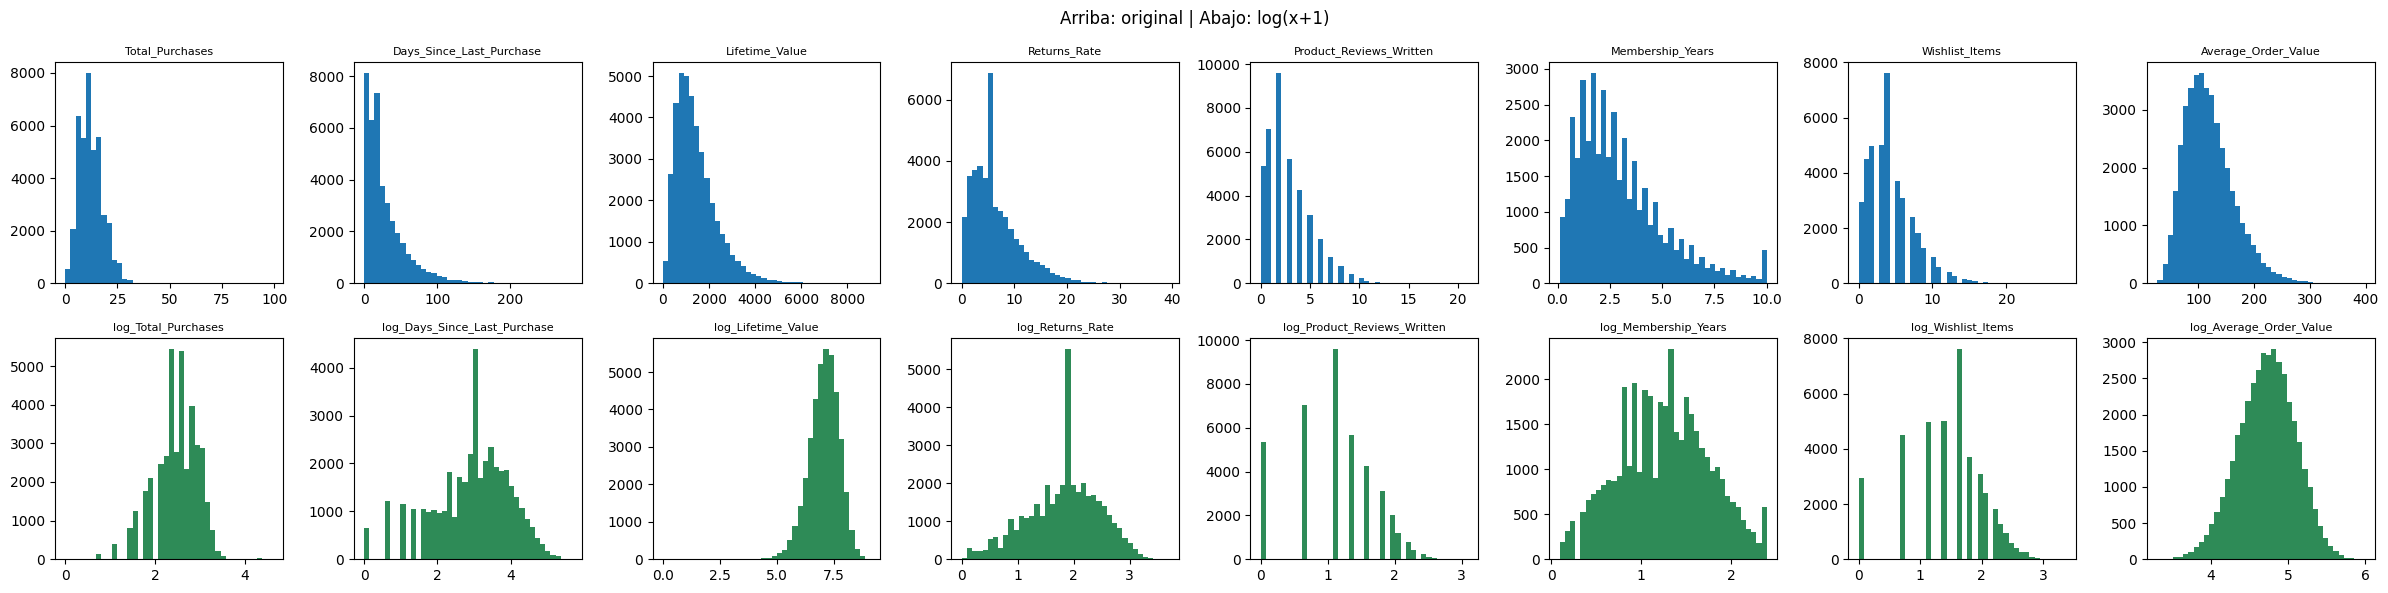

In [ ]:
fig, axs = plt.subplots(2, 8, figsize=(24, 6))
for i, c in enumerate(VARS_LOG):
    axs[0, i].hist(train[c], bins=40); axs[0, i].set_title(c, fontsize=8)
    axs[1, i].hist(train_log['log_' + c], bins=40, color='seagreen'); axs[1, i].set_title('log_' + c, fontsize=8)
plt.suptitle('Arriba: original | Abajo: log(x+1)')
plt.tight_layout()
plt.show()

En las ocho variables el sesgo baja a menos de 0.65 en valor absoluto (por ejemplo, Total_Purchases de 2.60 a −0.50 y Days_Since_Last_Purchase de 2.09 a −0.56). Las distribuciones quedan mucho más simétricas.

Paso 4. Guardar los datos con coma decimal, igual que los que se suben a SAS: el train limpio con logaritmos y el test solo con logaritmos.

In [ ]:
train_log.to_csv('train_limpio_log.csv', index=False, decimal=',')
test_log.to_csv('test_log.csv', index=False, decimal=',')
print('Archivos guardados: train_limpio_log.csv y test_log.csv')

Archivos guardados: train_limpio_log.csv y test_log.csv


# Parte 7. Selección de variables, codificación y escalado

## 7.1 Selección de variables
En SAS Model Studio se eligieron las variables en dos rondas: primero se quitaron 8 y después 5 que casi no aportaban al gradient boosting. Quedaron 11 de 24: log_Lifetime_Value, Cart_Abandonment_Rate, Customer_Service_Calls, Discount_Usage_Rate, log_Days_Since_Last_Purchase, Age, Email_Open_Rate, log_Total_Purchases, log_Returns_Rate, Pages_Per_Session y City.

Para comprobarlo en Python, se compara el gradient boosting con las 24 variables y con las 11, usando validación cruzada de 10 grupos en el train.

In [ ]:
from sklearn.model_selection import cross_val_score

In [ ]:
NUMERICAS = ['log_Lifetime_Value', 'Cart_Abandonment_Rate', 'Customer_Service_Calls', 'Discount_Usage_Rate',
             'log_Days_Since_Last_Purchase', 'Age', 'Email_Open_Rate', 'log_Total_Purchases',
             'log_Returns_Rate', 'Pages_Per_Session']
CATEGORICAS = ['City']

TODAS = [c for c in train_log.columns if c != OBJ]
ONCE = NUMERICAS + CATEGORICAS

kfold = KFold(n_splits=10, random_state=SEMILLA, shuffle=True)
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEMILLA)

for nombre, variables in [('24 variables', TODAS), ('11 variables', ONCE)]:
    X = pd.get_dummies(train_log[variables], columns=[c for c in variables if c in CAT], dtype=int)
    auc = cross_val_score(gb, X, train_log[OBJ], cv=kfold, scoring='roc_auc')
    print(f'{nombre}: AUC {auc.mean():.4f}')

24 variables: AUC 0.9258
11 variables: AUC 0.9234


Con las 11 variables el AUC baja apenas de 0.9255 a 0.9235: el modelo pierde muy poco y usa menos de la mitad de las variables. Se usan las 11 porque es el mismo modelo final de SAS y el mismo que usa el dashboard para predecir. Las variables que no se usan en train tampoco se usan en test.

In [ ]:
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_score

## 7.2 Codificación y escalado
City es categórica, así que se convierte en columnas de 0 y 1 (one-hot encoding). Después se estandarizan las variables, como en clase, para que todas tengan una escala parecida. Esto lo necesitan la regresión logística y la red neuronal; a los árboles no les afecta. El escalador se ajusta solo con el train.

El test conserva sus vacíos (no se limpió). El árbol, el bosque y el gradient boosting pueden recibir vacíos, pero la regresión logística y la red neuronal no. Para esos dos modelos se prepara una copia del test con los vacíos rellenados con la mediana del train. El archivo de test no se modifica y no se usa nada del test para calcular.

In [ ]:
X_train = pd.get_dummies(train_log[NUMERICAS + CATEGORICAS], columns=CATEGORICAS, dtype=int)
X_test = pd.get_dummies(test_log[NUMERICAS + CATEGORICAS], columns=CATEGORICAS, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)     # mismas columnas que train
Y_train = train_log[OBJ]
Y_test = test_log[OBJ]

# copia del test con los vacios rellenados con la mediana del train (solo para logistica y red neuronal)
X_test_lleno = X_test.fillna(X_train.median())

escalador = StandardScaler().fit(X_train)       # se ajusta solo con train
X_train = pd.DataFrame(escalador.transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(escalador.transform(X_test), columns=X_test.columns)
X_test_lleno = pd.DataFrame(escalador.transform(X_test_lleno), columns=X_test_lleno.columns)

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Clientes del test con algún vacío:', X_test.isnull().any(axis=1).sum())

X_train: (40000, 50) | X_test: (10000, 50)
Clientes del test con algún vacío: 3256


# Parte 8. Los cinco modelos y validación cruzada

- Regresión logística: modelo lineal; da la probabilidad con una función sigmoide.
- Árbol de decisión: reglas tipo "si carrito abandonado > X y llamadas > Y". Se limita la profundidad (6 niveles) para que no memorice el train.
- Bosque aleatorio: 200 árboles con muestras y variables al azar; se promedian sus votos.
- Red neuronal (MLP): una capa oculta de 32 neuronas, con paro temprano para no sobreajustar.
- Gradient boosting: árboles pequeños en secuencia; cada uno corrige los errores del anterior. Fue el campeón en SAS.

Igual que en clase, cada modelo se evalúa con validación cruzada de 10 grupos (KFold) dentro del train. Se mide el accuracy y el AUC. Esta celda tarda unos minutos.

In [ ]:
models = []
models.append(('Regresión logística', LogisticRegression(max_iter=1000)))
models.append(('Árbol de decisión', DecisionTreeClassifier(criterion='gini', max_depth=6, min_samples_leaf=50, random_state=SEMILLA)))
models.append(('Bosque aleatorio', RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEMILLA)))
models.append(('Red neuronal', MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, early_stopping=True, random_state=SEMILLA)))
models.append(('Gradient Boosting', HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEMILLA)))

results = []
results_auc = []
names = []

for name, model in models:
    kfold = KFold(n_splits=10, random_state=SEMILLA, shuffle=True)
    cv_result = cross_val_score(model, X_train, Y_train, cv=kfold, scoring='accuracy')
    cv_auc = cross_val_score(model, X_train, Y_train, cv=kfold, scoring='roc_auc')
    names.append(name)
    results.append(cv_result)
    results_auc.append(cv_auc)

for i in range(len(names)):
    print(names[i], '| accuracy:', round(results[i].mean(), 4), '| AUC:', round(results_auc[i].mean(), 4))

Regresión logística | accuracy: 0.7655 | AUC: 0.7679
Árbol de decisión | accuracy: 0.8796 | AUC: 0.8954
Bosque aleatorio | accuracy: 0.9098 | AUC: 0.9205
Red neuronal | accuracy: 0.8742 | AUC: 0.9
Gradient Boosting | accuracy: 0.9133 | AUC: 0.9234


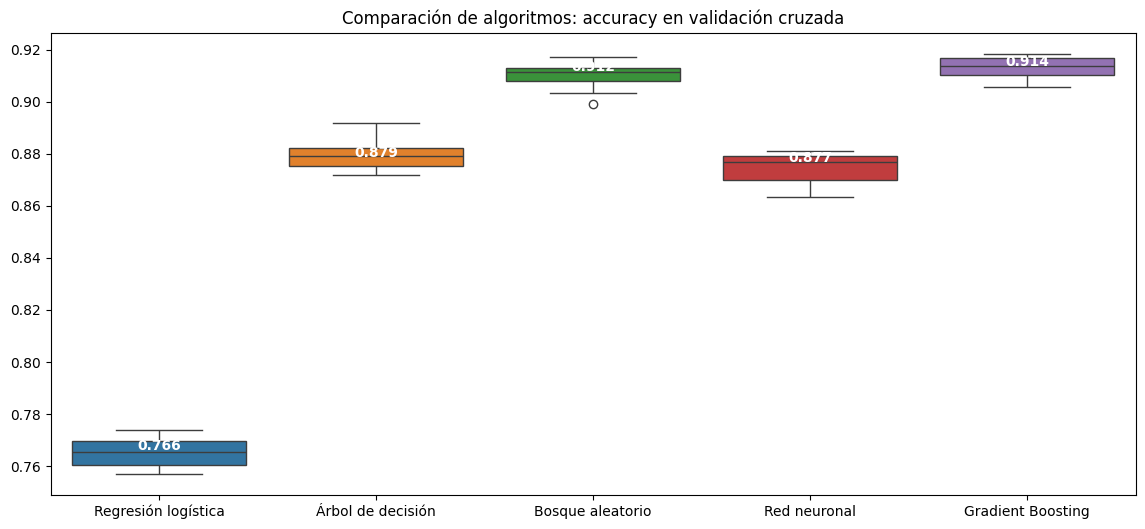

In [ ]:
# visualizacion de resultados para compararlos (como en clase)
medians = [round(np.median(r), 3) for r in results]

fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=results, ax=ax)
ax.set_xticklabels(names)
for x in ax.get_xticks():
    ax.text(x, medians[x], medians[x], horizontalalignment='center', color='white', weight='bold')
plt.title('Comparación de algoritmos: accuracy en validación cruzada')
plt.show()

El gradient boosting tiene el mejor accuracy (0.913) y el mejor AUC (0.924) en la validación cruzada, seguido muy de cerca por el bosque aleatorio (0.910 y 0.921). Después vienen el árbol de decisión (0.880) y la red neuronal (0.874). La regresión logística queda muy abajo (0.766): una frontera lineal no alcanza a capturar combinaciones como "carrito alto y muchas llamadas". Las cajas son angostas, así que los resultados son estables entre los 10 grupos.

# Parte 9. Evaluación en el test (20%)
Cada modelo se entrena con todo el train y se califica con el test, que no participó en nada de lo anterior y no se limpió. Se usa el corte de 0.5, la misma regla de decisión de SAS: si la probabilidad de abandono es mayor a 0.5, el cliente recibe la campaña. La regresión logística y la red neuronal usan la copia del test con los vacíos rellenados (Parte 7.2).

Para cada modelo se muestra la matriz de confusión y, como en clase, las métricas calculadas a partir de ella:
- Accuracy: porcentaje de clientes bien clasificados.
- Error de clasificación: porcentaje mal clasificado.
- Recall: de los que sí se fueron, cuántos detectó el modelo.
- Precisión: de los que el modelo marca como "se va", cuántos sí se fueron.
- Especificidad: de los que se quedaron, cuántos identificó bien.

Evaluando Regresión logística con el test
-----------------------------------------


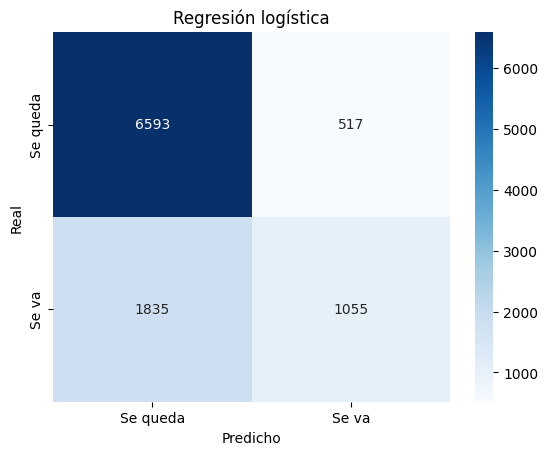

Accuracy: 0.7648
Error de clasificación: 0.2352
Recall: 0.3651
Precisión: 0.6711
Especificidad: 0.9273
              precision    recall  f1-score   support

           0       0.78      0.93      0.85      7110
           1       0.67      0.37      0.47      2890

    accuracy                           0.76     10000
   macro avg       0.73      0.65      0.66     10000
weighted avg       0.75      0.76      0.74     10000

Evaluando Árbol de decisión con el test
-----------------------------------------


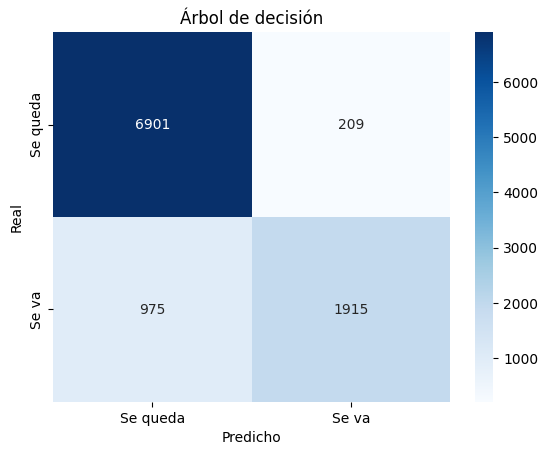

Accuracy: 0.8816
Error de clasificación: 0.1184
Recall: 0.6626
Precisión: 0.9016
Especificidad: 0.9706
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      7110
           1       0.90      0.66      0.76      2890

    accuracy                           0.88     10000
   macro avg       0.89      0.82      0.84     10000
weighted avg       0.88      0.88      0.88     10000

Evaluando Bosque aleatorio con el test
-----------------------------------------


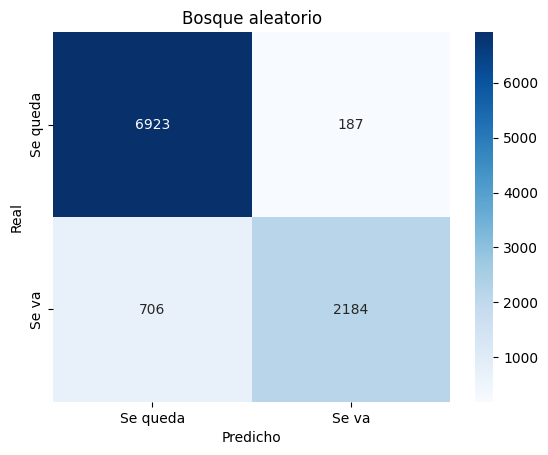

Accuracy: 0.9107
Error de clasificación: 0.0893
Recall: 0.7557
Precisión: 0.9211
Especificidad: 0.9737
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7110
           1       0.92      0.76      0.83      2890

    accuracy                           0.91     10000
   macro avg       0.91      0.86      0.88     10000
weighted avg       0.91      0.91      0.91     10000

Evaluando Red neuronal con el test
-----------------------------------------


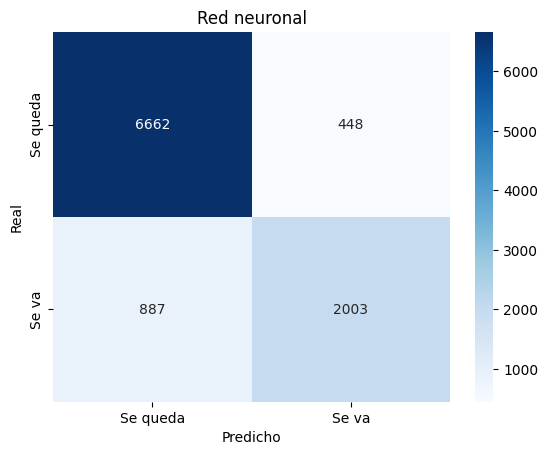

Accuracy: 0.8665
Error de clasificación: 0.1335
Recall: 0.6931
Precisión: 0.8172
Especificidad: 0.9370
              precision    recall  f1-score   support

           0       0.88      0.94      0.91      7110
           1       0.82      0.69      0.75      2890

    accuracy                           0.87     10000
   macro avg       0.85      0.82      0.83     10000
weighted avg       0.86      0.87      0.86     10000

Evaluando Gradient Boosting con el test
-----------------------------------------


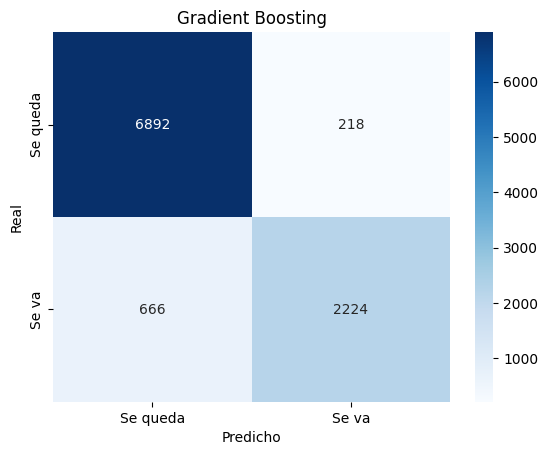

Accuracy: 0.9116
Error de clasificación: 0.0884
Recall: 0.7696
Precisión: 0.9107
Especificidad: 0.9693
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7110
           1       0.91      0.77      0.83      2890

    accuracy                           0.91     10000
   macro avg       0.91      0.87      0.89     10000
weighted avg       0.91      0.91      0.91     10000



In [ ]:
label = ['Se queda', 'Se va']
NECESITAN_LLENO = ['Regresión logística', 'Red neuronal']

FPR = []
TPR = []
Y_scores = []
filas = []

for name, model in models:
    model.fit(X_train, Y_train)
    datos_test = X_test_lleno if name in NECESITAN_LLENO else X_test
    Y_score = model.predict_proba(datos_test)[:, 1]      # probabilidad de abandono
    Y_predict = (Y_score > 0.5).astype(int)               # regla de decision

    print(f'Evaluando {name} con el test')
    print('-----------------------------------------')

    # matriz de confusion
    confusion = confusion_matrix(Y_test, Y_predict)
    sns.heatmap(confusion, annot=True, xticklabels=label, yticklabels=label, fmt='', cmap='Blues')
    plt.xlabel('Predicho')
    plt.ylabel('Real')
    plt.title(name)
    plt.show()

    # valores de la matriz de confusion
    TP = confusion[1, 1]
    TN = confusion[0, 0]
    FP = confusion[0, 1]
    FN = confusion[1, 0]

    print(f'Accuracy: {(TP + TN) / (TP + TN + FP + FN):.4f}')
    print(f'Error de clasificación: {(FP + FN) / (TP + TN + FP + FN):.4f}')
    print(f'Recall: {TP / (TP + FN):.4f}')
    print(f'Precisión: {TP / (TP + FP):.4f}')
    print(f'Especificidad: {TN / (TN + FP):.4f}')
    print(classification_report(Y_test, Y_predict))

    # para la curva ROC
    fpr, tpr, cortes = roc_curve(Y_test, Y_score)
    FPR.append(fpr)
    TPR.append(tpr)
    Y_scores.append(Y_score)

    filas.append([name, accuracy_score(Y_test, Y_predict), precision_score(Y_test, Y_predict),
                  recall_score(Y_test, Y_predict), f1_score(Y_test, Y_predict),
                  roc_auc_score(Y_test, Y_score), np.max(tpr - fpr)])

Tabla comparativa de los cinco modelos en el test. El KS es la máxima separación entre los clientes que se van y los que se quedan; es la métrica que usa SAS para elegir al campeón.

In [ ]:
comparativa = pd.DataFrame(filas, columns=['Modelo', 'Accuracy', 'Precisión', 'Recall', 'F1', 'AUC', 'KS'])
comparativa = comparativa.set_index('Modelo').round(4).sort_values('AUC', ascending=False)
comparativa

,Accuracy,Precisión,Recall,F1,AUC,KS
Modelo,,,,,,
Gradient Boosting,0.9116,0.9107,0.7696,0.8342,0.9243,0.7721
Bosque aleatorio,0.9107,0.9211,0.7557,0.8303,0.9236,0.7692
Árbol de decisión,0.8816,0.9016,0.6626,0.7639,0.8988,0.6897
Red neuronal,0.8665,0.8172,0.6931,0.7500,0.8985,0.6816
Regresión logística,0.7648,0.6711,0.3651,0.4729,0.7704,0.4085


El gradient boosting gana en accuracy (0.912), recall (0.769), F1 (0.835), AUC (0.924) y KS (0.773). El bosque aleatorio queda casi empatado en AUC (0.924) y tiene un poco más de precisión (0.921 contra 0.913), pero detecta menos clientes que se van. Todos los modelos identifican muy bien a los que se quedan (especificidad de 0.93 a 0.97); la diferencia está en cuántos de los que se van detectan.

# Parte 10. Curva ROC
La curva ROC muestra, para todos los cortes posibles, cuántos de los que se van detecta el modelo (eje y) contra cuántos de los que se quedan marca por error (eje x). Mientras más se pegue a la esquina superior izquierda, mejor. La línea roja es un modelo al azar (AUC = 0.5).

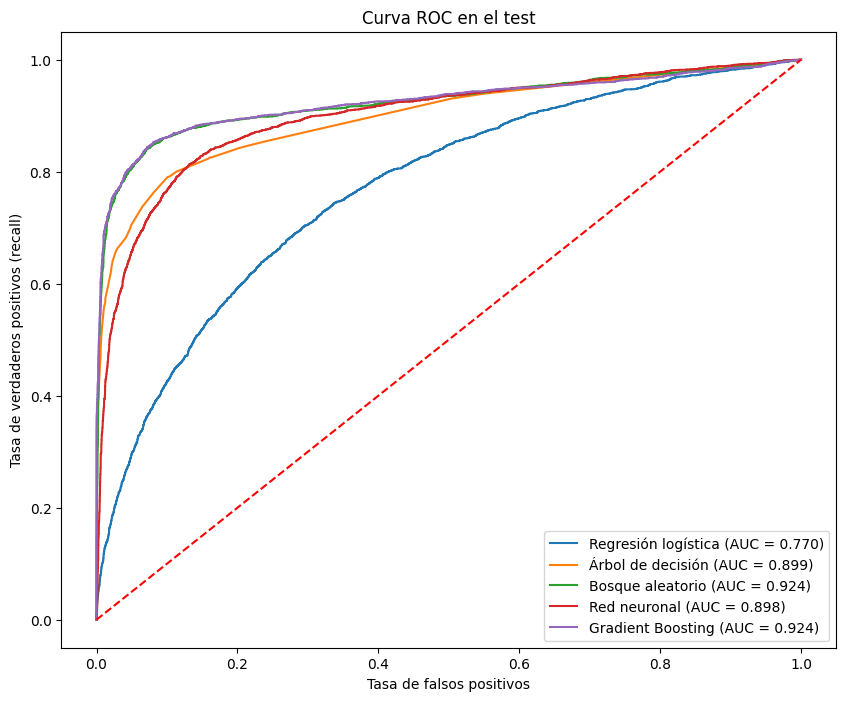

In [ ]:
plt.figure(figsize=(10, 8))
for i in range(len(FPR)):
    plt.plot(FPR[i], TPR[i], label=f'{names[i]} (AUC = {roc_auc_score(Y_test, Y_scores[i]):.3f})')

# linea de referencia
sns.lineplot(x=[0, 1], y=[0, 1], color='red', linestyle='--')
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curva ROC en el test')
plt.legend(loc=4)
plt.show()

El gradient boosting y el bosque aleatorio casi se enciman (AUC 0.924): son los que mejor separan a los clientes que se van. La red neuronal y el árbol quedan un poco abajo (0.899) y la regresión logística muy lejos (0.770).

# Parte 11. Modelo campeón: gradient boosting
El gradient boosting es el campeón en la validación cruzada y lo sostiene en el test, igual que en SAS. Se comparan sus resultados con los de SAS Model Studio. Los de SAS son de su partición de validación (30% del train), así que se esperan números parecidos pero no idénticos.

In [ ]:
gb_test = comparativa.loc['Gradient Boosting']
pd.DataFrame({'SAS (validación)': [0.9169, 0.9234, 0.7734],
              'Python (test)': [gb_test['Accuracy'], gb_test['AUC'], gb_test['KS']]},
             index=['Accuracy', 'AUC', 'KS']).round(4)

,SAS (validación),Python (test)
Accuracy,0.9169,0.9116
AUC,0.9234,0.9243
KS,0.7734,0.7721


Los resultados casi coinciden: accuracy 0.912 contra 0.917, AUC 0.924 contra 0.923 y KS 0.773 igual en los dos. El modelo funciona igual aunque el test llegue sin limpiar.

Para entender cómo decide un modelo de árboles, se dibujan los primeros niveles del árbol de decisión (como en clase). Los cortes están en escala estandarizada: 0 es el promedio y 1 es una desviación estándar arriba.

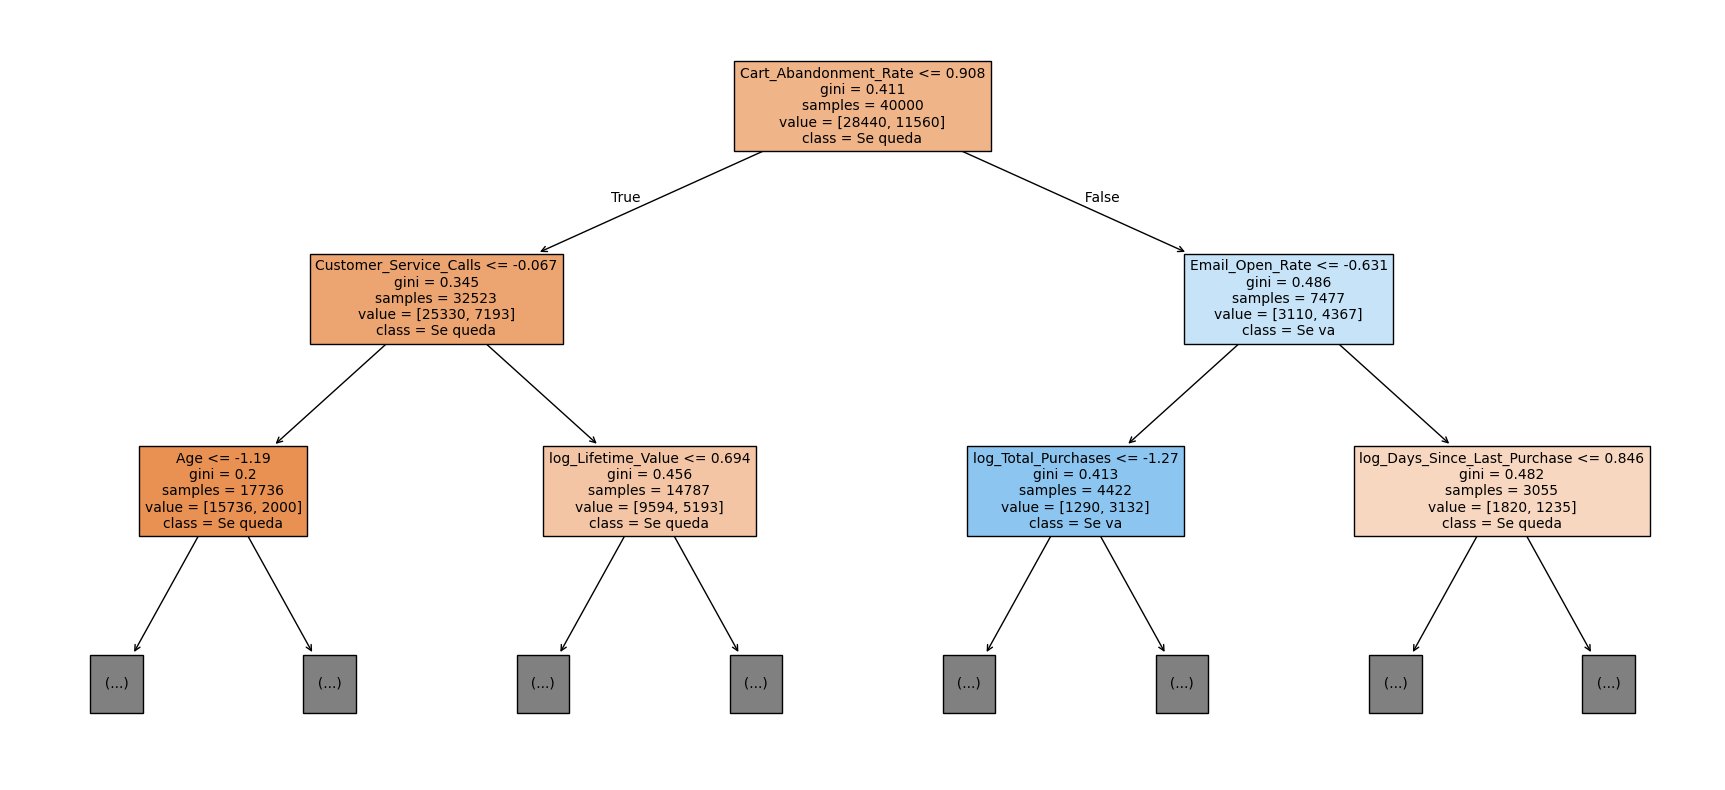

In [ ]:
from sklearn import tree

arbol = dict(models)['Árbol de decisión']
plt.figure(figsize=(22, 10))
tree.plot_tree(arbol, feature_names=list(X_train.columns), class_names=label, filled=True, max_depth=2, fontsize=10)
plt.show()

La primera pregunta del árbol es el carrito abandonado y la segunda, las llamadas a servicio: las mismas dos variables de la regla de riesgo del dashboard (carrito > 71.25% y 6 o más llamadas). Los clientes con carrito alto caen casi todos en "Se va".

Por último, qué variables usa más el gradient boosting. Se revuelve una variable a la vez y se mide cuánto baja el AUC: si baja mucho, el modelo depende de esa variable.

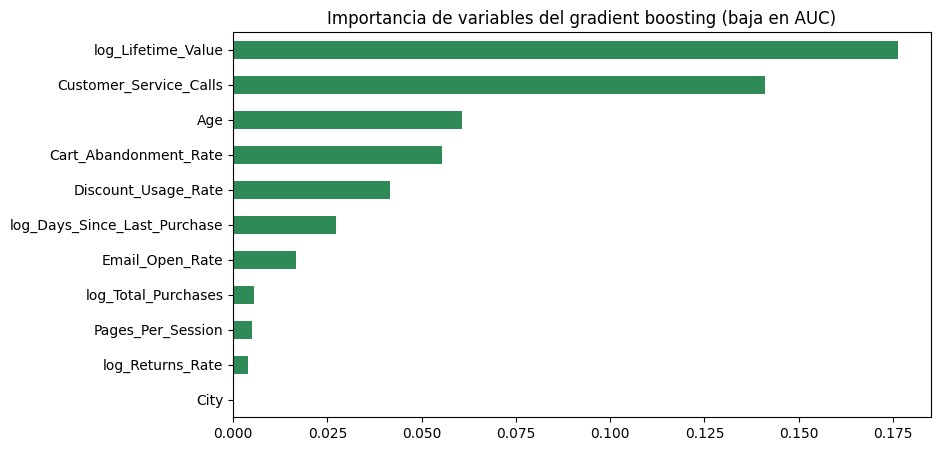

In [ ]:
gb = dict(models)['Gradient Boosting']
imp = permutation_importance(gb, X_test, Y_test, scoring='roc_auc', n_repeats=5, random_state=SEMILLA)
importancia = pd.Series(imp.importances_mean, index=X_test.columns)

# las columnas de City se suman en una sola variable
importancia = importancia.groupby(lambda c: 'City' if c.startswith('City_') else c).sum().sort_values()
importancia.plot(kind='barh', figsize=(9, 5), color='seagreen')
plt.title('Importancia de variables del gradient boosting (baja en AUC)')
plt.show()

Las variables que más pesan son el valor de vida del cliente (log_Lifetime_Value), las llamadas a servicio, la edad y el carrito abandonado. City casi no aporta.

# Parte 12. Guardar resultados para el dashboard
Se guardan la tabla comparativa y los puntos de la curva ROC de cada modelo, para la pestaña del modelo en Streamlit.

In [ ]:
comparativa.to_csv('comparativa_modelos.csv')

filas_roc = []
for i in range(len(names)):
    filas_roc.append(pd.DataFrame({'Modelo': names[i], 'FPR': FPR[i], 'TPR': TPR[i]}))
pd.concat(filas_roc).round(5).to_csv('roc_modelos.csv', index=False)

importancia.sort_values(ascending=False).rename('Baja del AUC').to_csv('importancia_gb.csv')
print('Archivos guardados: comparativa_modelos.csv, roc_modelos.csv e importancia_gb.csv')

Archivos guardados: comparativa_modelos.csv, roc_modelos.csv e importancia_gb.csv


# Conclusión
El dataset crudo tenía errores escondidos: compras multiplicadas por 1.3, descuentos multiplicados por 1.2, tickets promedio inflados, edades y porcentajes imposibles, y filas con devoluciones inventadas. Se encontraron paso a paso y se corrigieron solo en el train (80%). Los faltantes se imputaron según su significado: con la mediana del train, o con la mediana de su grupo de actividad en Email_Open_Rate y Session_Duration_Avg. El test (20%) no se limpió; solo se le aplicó el logaritmo, como indicó el profesor.

Con las 11 variables del modelo final de SAS, el gradient boosting es el campeón: accuracy 0.912, AUC 0.924 y KS 0.773 en el test, casi igual que en SAS (0.917, 0.923 y 0.773). Detecta al 77% de los clientes que se van y 9 de cada 10 clientes que marca sí se iban. Que funcione con datos sin limpiar indica que el modelo es robusto.

Limitaciones: los parámetros de los modelos no se optimizaron con búsqueda en rejilla; algunos descuentos multiplicados por 1.2 no se pueden detectar; 397 clientes tienen una antigüedad que no cuadra con su edad; y la imputación con la mediana crea picos en el valor imputado.